# پروژهٔ PT1 — تشخیص فعالیت‌های انسانی با دادهٔ WISDM

**درس یادگیری ماشین | آشنایی با داده‌ها، تحلیل اکتشافی و مدل پایه**

این نوت‌بوک تمام مراحل خواسته‌شده در صورت تمرین را به‌صورت تکرارپذیر اجرا می‌کند: بررسی دادهٔ خام، تحلیل اکتشافی، مقایسهٔ سیگنال‌ها و تفاوت‌های فردی، پنجره‌بندی، تفکیک Subject-wise، مدل Majority Class، رگرسیون لجستیک، و گزارش معیارها.

> **پیش‌نیاز داده:** فایل خامی که مدرس برای همین تمرین ارائه کرده است باید در مسیر `data/WISDM_ar_v1.1_raw.txt` قرار بگیرد. نسخهٔ صورت تمرین ۲۶ شرکت‌کننده را ذکر می‌کند؛ بنابراین به‌جای جایگزین‌کردن بی‌بررسی فایل عمومی ۳۶‌نفره، از فایل مخصوص کلاس استفاده کنید. نوت‌بوک تعداد کاربران را کنترل و در صورت اختلاف هشدار می‌دهد.

## اجرای پروژه
1. فایل خام را داخل پوشهٔ `data/` قرار دهید.
2. وابستگی‌ها را با `pip install -r requirements.txt` نصب کنید.
3. سلول‌ها را از ابتدا تا انتها اجرا کنید.
4. داشبورد را جداگانه با `streamlit run dashboard.py` اجرا کنید.

تمام اعداد، نمودارها و معیارهای مدل از دادهٔ واقعیِ فایل ورودی محاسبه می‌شوند؛ هیچ خروجی ساختگی یا نتیجهٔ از پیش‌ساخته در این نوت‌بوک قرار داده نشده است.

## ۰. تصمیم‌های روش‌شناختی مهم

- هر رکورد شامل یک لحظهٔ زمانی و سه مؤلفهٔ هم‌زمان `X/Y/Z` است؛ این سه ستون سه گام زمانی جداگانه نیستند.
- زمان `Timestamp` را زمان سپری‌شده/ساعت مطلق فرض نمی‌کنیم؛ تنها برای مرتب‌سازی نمونه‌ها درون هر شرکت‌کننده از آن استفاده می‌کنیم.
- پنجره‌ها با طول ۵۱ و گام ۲۶ ساخته می‌شوند؛ یعنی مدت تقریبی پنجره ۲٫۵۵ ثانیه و هم‌پوشانی پنجره‌های متوالی ۲۵ نمونه (حدود ۴۹٪) است.
- پنجره از مرز شرکت‌کننده یا فعالیت عبور نمی‌کند. تغییر برچسب فعالیت و وقفهٔ زمانی غیرعادی نیز مرز قطعه محسوب می‌شود.
- تقسیم آموزش/اعتبارسنجی/آزمون بر اساس شناسهٔ شرکت‌کننده است، نه تقسیم تصادفی پنجره‌ها.
- `StandardScaler` فقط روی آموزش fit می‌شود؛ تنظیم `C` با اعتبارسنجی انجام می‌شود و آزمون فقط برای ارزیابی نهایی است.
- نقاط پرت آماری به‌طور خودکار حذف نمی‌شوند؛ ابتدا گزارش می‌شوند تا حذف دادهٔ معتبر به اشتباه رخ ندهد.

## ۱. نصب و واردکردن کتابخانه‌ها

In [2]:
# در صورت نیاز، این دستور را در ترمینال اجرا کنید:
# %pip install -r requirements.txt

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score
)
from IPython.display import display

from pt1_utils import (
    ACTIVITY_ORDER, AXES, load_wisdm_data, outlier_audit,
    make_windows, subject_wise_split, split_summary
)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path(r"C:\Users\Zohreh\Downloads\data\WISDM_ar_v1.1\WISDM_ar_v1.1_raw.txt")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("مسیر داده:", DATA_PATH.resolve())

مسیر داده: C:\Users\Zohreh\Downloads\data\WISDM_ar_v1.1\WISDM_ar_v1.1_raw.txt


In [3]:
print("آیا فایل وجود دارد؟", DATA_PATH.exists())

if DATA_PATH.exists():
    print("حجم فایل (MB):", round(DATA_PATH.stat().st_size / (1024**2), 2))
else:
    print("فایل پیدا نشد!")

آیا فایل وجود دارد؟ True
حجم فایل (MB): 47.99


In [4]:
import pandas as pd

columns = ["User", "Activity", "Timestamp", "X", "Y", "Z"]

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    sep=",",
    on_bad_lines="skip"
)

print("تعداد رکوردها:", len(df))
print("\nپنج رکورد اول:")
display(df.head())

تعداد رکوردها: 1086466

پنج رکورد اول:


,User,Activity,Timestamp,X,Y,Z
0,33,Jogging,49105962326000,-0.694638,12.680544,0.50395286;
1,33,Jogging,49106062271000,5.012288,11.264028,0.95342433;
2,33,Jogging,49106112167000,4.903325,10.882658,-0.08172209;
3,33,Jogging,49106222305000,-0.612916,18.496431,3.0237172;
4,33,Jogging,49106332290000,-1.184970,12.108489,7.205164;


In [5]:
# حذف نقطه‌ویرگول انتهای مقادیر محور Z
df["Z"] = df["Z"].astype(str).str.strip().str.rstrip(";")

# تبدیل سه محور به مقادیر عددی
for col in ["X", "Y", "Z"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# بررسی ساختار داده‌ها
print("ابعاد دیتاست:", df.shape)

print("\nنوع داده ستون‌ها:")
print(df.dtypes)

print("\nتعداد مقادیر گمشده:")
print(df.isna().sum())

print("\nتعداد کاربران:", df["User"].nunique())

print("\nفعالیت‌های موجود:")
print(df["Activity"].value_counts())

print("\nپنج ردیف اول پس از اصلاح:")
display(df.head())

ابعاد دیتاست: (1086466, 6)

نوع داده ستون‌ها:
User           int64
Activity         str
Timestamp      int64
X            float64
Y            float64
Z            float64
dtype: object

تعداد مقادیر گمشده:
User         0
Activity     0
Timestamp    0
X            0
Y            0
Z            1
dtype: int64

تعداد کاربران: 36

فعالیت‌های موجود:
Activity
Walking       418394
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394
Name: count, dtype: int64

پنج ردیف اول پس از اصلاح:


,User,Activity,Timestamp,X,Y,Z
0,33,Jogging,49105962326000,-0.694638,12.680544,0.503953
1,33,Jogging,49106062271000,5.012288,11.264028,0.953424
2,33,Jogging,49106112167000,4.903325,10.882658,-0.081722
3,33,Jogging,49106222305000,-0.612916,18.496431,3.023717
4,33,Jogging,49106332290000,-1.184970,12.108489,7.205164


In [6]:
# نمایش ردیف‌هایی که مقدار گمشده دارند
missing_rows = df[df.isna().any(axis=1)]

print("تعداد ردیف‌های دارای مقدار گمشده:", len(missing_rows))

display(missing_rows)

# نمایش توزیع کامل فعالیت‌ها
print("\nتعداد رکوردها در هر فعالیت:")
print(df["Activity"].value_counts().to_string())

# بررسی آخرین ردیف‌های دیتاست
print("\nآخرین 5 ردیف دیتاست:")
display(df.tail())

تعداد ردیف‌های دارای مقدار گمشده: 1


,User,Activity,Timestamp,X,Y,Z
343413,11,Walking,1867172313000,4.4,4.4,NaN



تعداد رکوردها در هر فعالیت:
Activity
Walking       418394
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394

آخرین 5 ردیف دیتاست:


,User,Activity,Timestamp,X,Y,Z
1086461,19,Sitting,131623331483000,9.00,-1.57,1.69
1086462,19,Sitting,131623371431000,9.04,-1.46,1.73
1086463,19,Sitting,131623411592000,9.08,-1.38,1.69
1086464,19,Sitting,131623491487000,9.00,-1.46,1.73
1086465,19,Sitting,131623531465000,8.88,-1.33,1.61


In [7]:
# ساخت نسخه پاک‌سازی‌شده برای تحلیل
df_clean = df.dropna(subset=["User", "Activity", "Timestamp", "X", "Y", "Z"]).copy()

print("تعداد رکوردهای خام:", len(df))
print("تعداد رکوردهای پاک‌سازی‌شده:", len(df_clean))
print("تعداد رکوردهای حذف‌شده:", len(df) - len(df_clean))

print("\nتعداد کاربران:", df_clean["User"].nunique())
print("\nتوزیع فعالیت‌ها:")
print(df_clean["Activity"].value_counts().to_string())

تعداد رکوردهای خام: 1086466
تعداد رکوردهای پاک‌سازی‌شده: 1086465
تعداد رکوردهای حذف‌شده: 1

تعداد کاربران: 36

توزیع فعالیت‌ها:
Activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394


In [10]:
# محاسبه تعداد رکوردها در هر فعالیت
activity_counts = df_clean["Activity"].value_counts()

print("تعداد رکوردها به تفکیک فعالیت:")
print(activity_counts.to_string())

تعداد رکوردها به تفکیک فعالیت:
Activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394


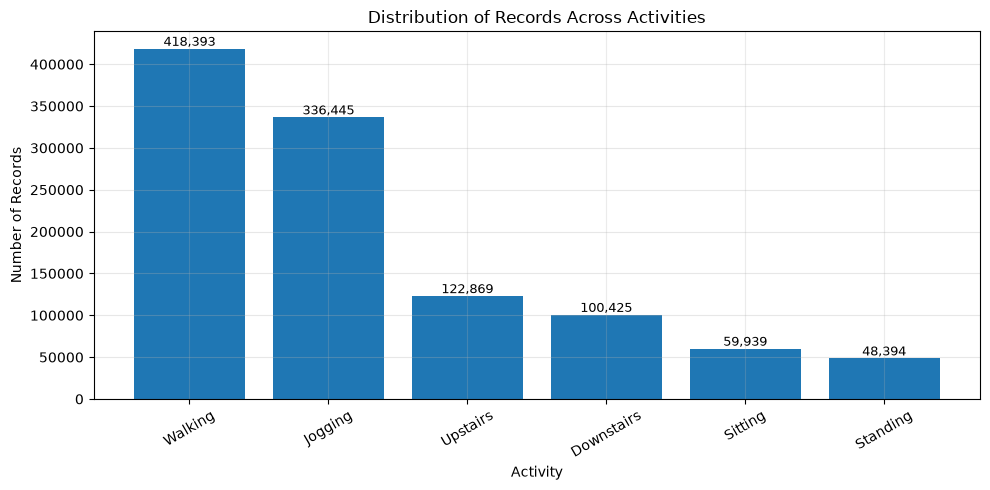

In [12]:
plt.figure(figsize=(10, 5))

bars = plt.bar(activity_counts.index, activity_counts.values)

plt.title("Distribution of Records Across Activities")
plt.xlabel("Activity")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)

# نمایش تعداد دقیق بالای هر میله
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

تعداد شرکت‌کنندگان: 36

تعداد رکوردهای هر شرکت‌کننده:
User
1     29978
2     23525
3     35161
4     11371
5     28509
6     29704
7     30967
8     41188
9     12923
10    34883
11    31658
12    32641
13    37092
14    38192
15    28154
16    20469
17    22020
18    32810
19    45383
20    56632
21    23703
22    22310
23    25673
24    25736
25    13468
26    32578
27    34957
28    21358
29    38245
30    25334
31    44282
32    35506
33    29453
34    35947
35    22394
36    32261


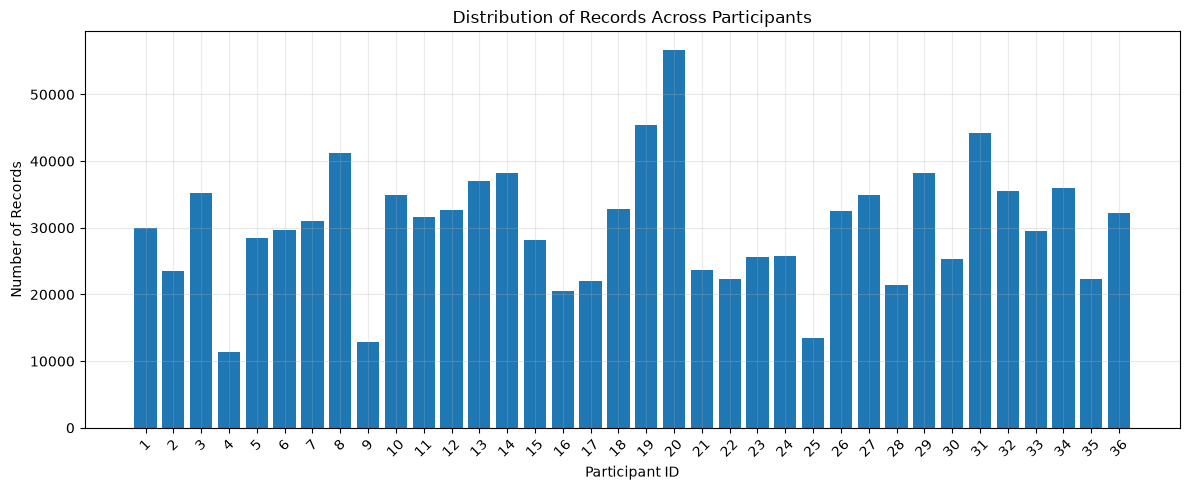


کمترین تعداد رکورد: 11371
بیشترین تعداد رکورد: 56632
میانگین تعداد رکورد: 30179.58


In [13]:
# تعداد رکوردهای هر شرکت‌کننده
user_counts = df_clean["User"].value_counts().sort_index()

print("تعداد شرکت‌کنندگان:", len(user_counts))
print("\nتعداد رکوردهای هر شرکت‌کننده:")
print(user_counts.to_string())

# رسم نمودار
plt.figure(figsize=(12, 5))

bars = plt.bar(user_counts.index.astype(str), user_counts.values)

plt.title("Distribution of Records Across Participants")
plt.xlabel("Participant ID")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nکمترین تعداد رکورد:", user_counts.min())
print("بیشترین تعداد رکورد:", user_counts.max())
print("میانگین تعداد رکورد:", round(user_counts.mean(), 2))

In [14]:
print("تعداد شرکت‌کنندگان:", user_counts.count())

print("کمترین تعداد رکورد:",
      user_counts.min(),
      "برای کاربر:", user_counts.idxmin())

print("بیشترین تعداد رکورد:",
      user_counts.max(),
      "برای کاربر:", user_counts.idxmax())

print("میانگین تعداد رکورد:",
      round(user_counts.mean(), 2))

print("انحراف معیار:",
      round(user_counts.std(), 2))

تعداد شرکت‌کنندگان: 36
کمترین تعداد رکورد: 11371 برای کاربر: 4
بیشترین تعداد رکورد: 56632 برای کاربر: 20
میانگین تعداد رکورد: 30179.58
انحراف معیار: 9311.67


## ۲. بارگذاری، پاک‌سازی محافظه‌کارانه و کنترل کیفیت

In [15]:
from pt1_utils import load_wisdm_data

In [16]:
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\Zohreh\Downloads\data\WISDM_ar_v1.1\WISDM_ar_v1.1_raw.txt"
)

print("آیا فایل وجود دارد؟", DATA_PATH.exists())
print("مسیر فایل:", DATA_PATH)

آیا فایل وجود دارد؟ True
مسیر فایل: C:\Users\Zohreh\Downloads\data\WISDM_ar_v1.1\WISDM_ar_v1.1_raw.txt


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

In [18]:
AXES = ["X", "Y", "Z"]

In [19]:
ACTIVITY_ORDER = [
    "Walking",
    "Jogging",
    "Upstairs",
    "Downstairs",
    "Sitting",
    "Standing"
]

In [20]:
import importlib
import pt1_utils

importlib.reload(pt1_utils)
load_wisdm_data = pt1_utils.load_wisdm_data

print("نسخه جدید تابع بارگذاری شد.")

نسخه جدید تابع بارگذاری شد.


In [21]:
data, audit = load_wisdm_data(DATA_PATH)

print("گزارش بارگذاری:")
display(pd.Series(audit, name="value").to_frame())

# صورت تمرین ۲۶ شرکت‌کننده را ذکر می‌کند؛ فقط هشدار می‌دهیم و داده‌ای را خودسرانه حذف نمی‌کنیم.
if audit["num_users"] != 26:
    warnings.warn(
        f"صورت تمرین ۲۶ شرکت‌کننده را ذکر می‌کند، اما فایل فعلی {audit['num_users']} شناسه دارد. "
        "مطمئن شوید فایل خام مخصوص همین کلاس را استفاده می‌کنید.",
        RuntimeWarning,
    )

print("ابعاد دادهٔ پاک‌شده:", data.shape)
print("شرکت‌کنندگان:", audit["num_users"], "| فعالیت‌ها:", audit["num_activities"])
display(data.head(10))

missing = data[["user_id", "activity", "timestamp", *AXES]].isna().sum()
print("مقادیر گمشده پس از پاک‌سازی:")
display(missing.to_frame("missing_count"))

print("برچسب‌های فعالیت موجود:", sorted(data["activity"].unique()))
assert set(data["activity"].unique()).issubset(set(ACTIVITY_ORDER))

# بررسی فاصلهٔ زمانی نمونه‌ها در واحد اصلی Timestamp (بدون فرض UTC یا تبدیل واحد)
positive_deltas = data.groupby("user_id")["timestamp"].diff()
positive_deltas = positive_deltas[positive_deltas > 0]
median_delta_by_user = positive_deltas.groupby(data.loc[positive_deltas.index, "user_id"]).median()
print("میانهٔ فاصلهٔ Timestamp در واحد اصلی فایل، به تفکیک کاربر:")
display(median_delta_by_user.describe().to_frame("median_timestamp_increment"))

گزارش بارگذاری:


,value
raw_lines,1098210
blank_lines,6
parsed_rows,1098209
repaired_lines,11733
joined_lines,5
invalid_records,0
missing_or_non_numeric_rows,1
unknown_activity_rows,0
exact_duplicate_rows,66820
clean_rows,1098208


ابعاد دادهٔ پاک‌شده: (1098208, 6)
شرکت‌کنندگان: 36 | فعالیت‌ها: 6


C:\Users\Zohreh\AppData\Local\Temp\ipykernel_8248\3736918991.py:8: RuntimeWarning: صورت تمرین ۲۶ شرکت‌کننده را ذکر می‌کند، اما فایل فعلی 36 شناسه دارد. مطمئن شوید فایل خام مخصوص همین کلاس را استفاده می‌کنید.
  warnings.warn(


,user_id,activity,timestamp,X,Y,Z
0,1,Walking,4991922345000,0.69,10.8,-2.03
1,1,Walking,4991972333000,6.85,7.44,-0.5
2,1,Walking,4992022351000,0.93,5.63,-0.5
3,1,Walking,4992072339000,-2.11,5.01,-0.69
4,1,Walking,4992122358000,-4.59,4.29,-1.95
5,1,Walking,4992172376000,12.41,11.18,7.82
6,1,Walking,4992222333000,17.27,11.6,5.94
7,1,Walking,4992272321000,1.42,8.43,-5.28
8,1,Walking,4992322339000,-2.68,15.89,-0.38
9,1,Walking,4992372327000,-1.38,9.92,-1.99


مقادیر گمشده پس از پاک‌سازی:


,missing_count
user_id,0
activity,0
timestamp,0
X,0
Y,0
Z,0


برچسب‌های فعالیت موجود: ['Downstairs', 'Jogging', 'Sitting', 'Standing', 'Upstairs', 'Walking']
میانهٔ فاصلهٔ Timestamp در واحد اصلی فایل، به تفکیک کاربر:


,median_timestamp_increment
count,3.600000e+01
mean,4.779892e+07
std,4.190124e+06
min,4.003900e+07
25%,4.998800e+07
50%,4.998800e+07
75%,5.001800e+07
max,5.004800e+07


In [22]:
print("تعداد رکوردها به تفکیک فعالیت:")
display(data["activity"].value_counts().reindex(ACTIVITY_ORDER))

print("تعداد رکوردها به تفکیک کاربر:")
display(data["user_id"].value_counts().sort_index())

تعداد رکوردها به تفکیک فعالیت:


activity
Walking       424399
Jogging       342179
Upstairs      122869
Downstairs    100427
Sitting        59939
Standing       48395
Name: count, dtype: int64

تعداد رکوردها به تفکیک کاربر:


user_id
1     29978
2     23525
3     35161
4     11371
5     28510
6     29704
7     30967
8     41188
9     12923
10    34883
11    31658
12    32641
13    37093
14    38192
15    28155
16    20470
17    22020
18    32812
19    45383
20    56632
21    35436
22    22310
23    25673
24    25736
25    13468
26    32578
27    34959
28    21358
29    38245
30    25335
31    44282
32    35506
33    29453
34    35948
35    22394
36    32261
Name: count, dtype: int64

In [23]:
# ساخت نسخه مرجع مطابق روش خواندن محافظه‌کارانه فایل خام

columns = ["user_id", "activity", "timestamp", "X", "Y", "Z"]

data_reference = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    sep=",",
    on_bad_lines="skip"
)

# پاک‌سازی انتهای ستون Z
data_reference["Z"] = (
    data_reference["Z"].astype(str).str.strip().str.rstrip(";")
)

# تبدیل ستون‌های عددی
for col in ["user_id", "timestamp", "X", "Y", "Z"]:
    data_reference[col] = pd.to_numeric(
        data_reference[col], errors="coerce"
    )

# حذف فقط رکوردهای دارای مقدار نامعتبر
data_reference = data_reference.dropna(
    subset=["user_id", "activity", "timestamp", "X", "Y", "Z"]
).copy()

data_reference["user_id"] = data_reference["user_id"].astype("int64")
data_reference["timestamp"] = data_reference["timestamp"].astype("int64")

data_reference = data_reference.sort_values(
    ["user_id", "timestamp"]
).reset_index(drop=True)

print("ابعاد نسخه مرجع:", data_reference.shape)
print("تعداد شرکت‌کنندگان:", data_reference["user_id"].nunique())
print("\nتوزیع فعالیت‌ها:")
display(data_reference["activity"].value_counts())

ابعاد نسخه مرجع: (1086465, 6)
تعداد شرکت‌کنندگان: 36

توزیع فعالیت‌ها:


activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394
Name: count, dtype: int64

In [24]:
# انتخاب نسخه مرجع برای ادامه تحلیل پروژه
data = data_reference.copy()

print("مجموعه داده اصلی پروژه انتخاب شد.")
print("ابعاد داده:", data.shape)
print("تعداد کاربران:", data["user_id"].nunique())
print("تعداد فعالیت‌ها:", data["activity"].nunique())

مجموعه داده اصلی پروژه انتخاب شد.
ابعاد داده: (1086465, 6)
تعداد کاربران: 36
تعداد فعالیت‌ها: 6


## ۳. توزیع فعالیت‌ها و شرکت‌کنندگان

In [25]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("پوشه خروجی آماده است:", OUTPUT_DIR.resolve())

پوشه خروجی آماده است: C:\Users\Zohreh\Downloads\the main project\outputs


,records,percent
activity,,
Walking,418393,38.509570
Jogging,336445,30.966943
Upstairs,122869,11.309062
Downstairs,100425,9.243280
Sitting,59939,5.516883
Standing,48394,4.454262


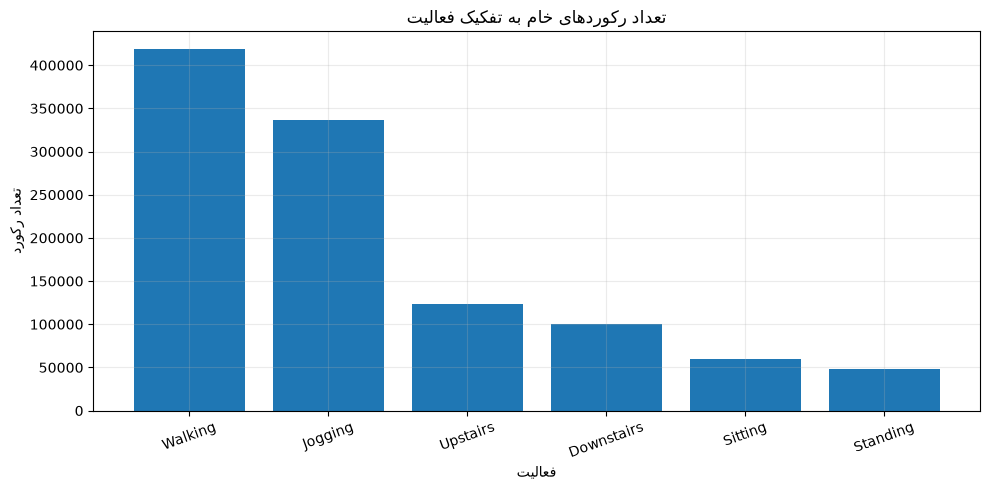

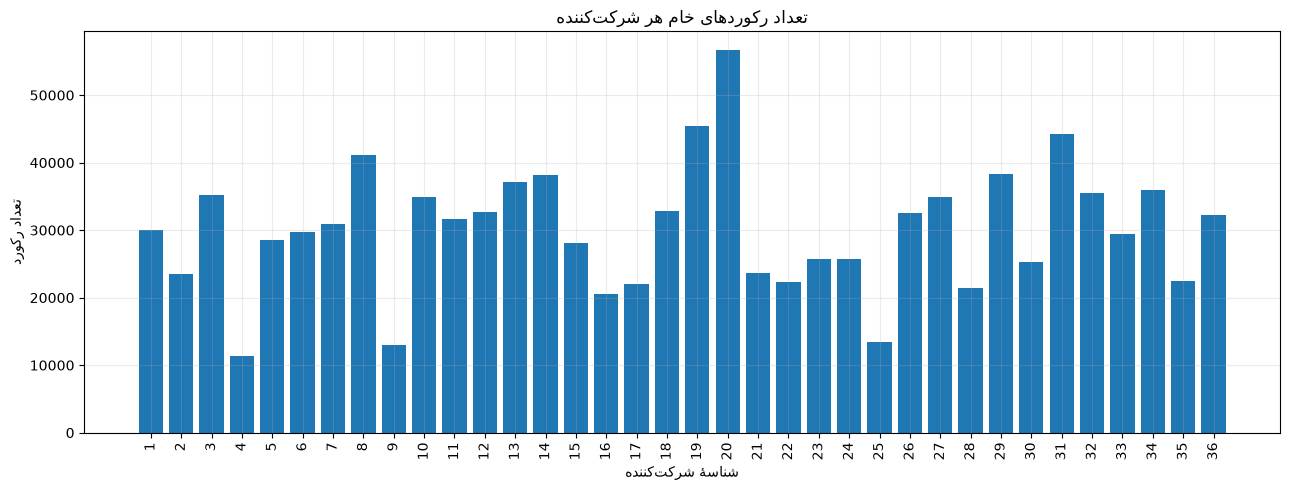

آمار تعداد رکورد بین شرکت‌کنندگان:


,records_per_subject
count,36.000000
mean,30179.583333
std,9311.672317
min,11371.000000
25%,23658.500000
50%,30472.500000
75%,35247.250000
max,56632.000000


بیشترین فعالیت: Walking
کمترین فعالیت: Standing
آیا توزیع فعالیت‌ها یکسان است؟ False
آیا همهٔ افراد تعداد رکورد یکسان دارند؟ False


In [26]:
activity_counts = (
    data["activity"].value_counts()
    .reindex(ACTIVITY_ORDER, fill_value=0)
    .rename("records")
    .to_frame()
)
activity_counts["percent"] = 100 * activity_counts["records"] / len(data)
display(activity_counts)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(activity_counts.index, activity_counts["records"])
ax.set(title="تعداد رکوردهای خام به تفکیک فعالیت", xlabel="فعالیت", ylabel="تعداد رکورد")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_activity_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

subject_counts = data.groupby("user_id").size().sort_index()
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(subject_counts.index.astype(str), subject_counts.values)
ax.set(title="تعداد رکوردهای خام هر شرکت‌کننده", xlabel="شناسهٔ شرکت‌کننده", ylabel="تعداد رکورد")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_subject_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print("آمار تعداد رکورد بین شرکت‌کنندگان:")
display(subject_counts.describe().to_frame("records_per_subject"))
print("بیشترین فعالیت:", activity_counts["records"].idxmax())
print("کمترین فعالیت:", activity_counts["records"].idxmin())
print("آیا توزیع فعالیت‌ها یکسان است؟", activity_counts["records"].nunique() == 1)
print("آیا همهٔ افراد تعداد رکورد یکسان دارند؟", subject_counts.nunique() == 1)

### تفسیر توزیع

در صورت نامتوازن بودن کلاس‌ها، طبقه‌بند ممکن است با پیش‌بینی مکرر کلاس پرتعداد به Accuracy ظاهراً مناسبی برسد، درحالی‌که کلاس‌های کم‌نمونه را ضعیف تشخیص دهد. به همین دلیل در بخش مدل علاوه بر Accuracy از Precision/Recall/F1 هر کلاس و Macro-F1 استفاده می‌کنیم. همچنین اختلاف تعداد رکورد بین افراد می‌تواند باعث شود مدل در عمل بیشتر با الگوی چند شرکت‌کنندهٔ پرتکرار مواجه شود.

## ۴. آمار توصیفی و بررسی مقادیر غیرعادی

In [27]:
from pt1_utils import outlier_audit

,mean,std,min,25%,50%,75%,max
X,0.664113,6.876277,-19.61,-2.910000,0.27,4.44,19.95
Y,7.246045,6.739789,-19.61,3.170000,7.93,11.56,20.04
Z,0.397697,4.761111,-19.80,-2.220117,0.00,2.72,19.61


X                                 Y                   \
                mean       std    min    max      mean       std    min   
activity                                                                  
Downstairs  0.471629  4.955956 -19.61  19.95  8.600225  4.904760 -19.61   
Jogging    -0.219109  9.168144 -19.61  19.95  5.434124  9.216889 -19.61   
Sitting     1.856270  4.759028 -10.31  12.45  1.853374  3.257750  -9.30   
Standing   -1.178245  3.235157 -10.99  13.10  8.987230  1.264784  -0.65   
Upstairs    0.381334  5.495272 -19.61  19.95  8.111545  4.890709 -19.61   
Walking     1.545899  5.825766 -19.61  19.91  8.695026  5.022420 -18.85   

                          Z                          
              max      mean       std    min    max  
activity                                             
Downstairs  20.04  0.684088  3.706783 -19.61  19.34  
Jogging     20.04 -0.150294  5.847291 -19.80  19.61  
Sitting     18.47  6.559716  3.735591 -10.80  13.99  
Standing    19.46  0.580127  1.376807  -4.14   7.25  
Upstairs    20.04  0.323542  3.567884 -19.61  19.19  
Walking     20.04 -0.112479  4.018524 -19.38  19.23

نامزدهای پرت با قاعدهٔ 1.5×IQR (حذف نشده‌اند):


,Q1,Q3,IQR,lower_fence,upper_fence,candidate_count,candidate_percent
axis,,,,,,,
X,-2.910000,4.44,7.350000,-13.935000,15.465000,66138,6.087449
Y,3.170000,11.56,8.390000,-9.415000,24.145000,19191,1.766371
Z,-2.220117,2.72,4.940117,-9.630291,10.130175,53250,4.901216


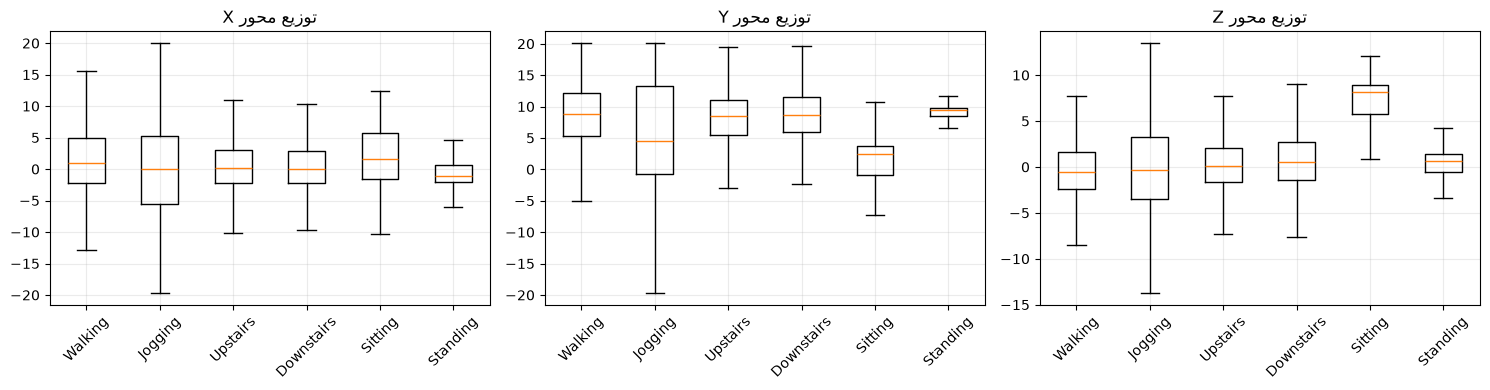

In [28]:
descriptive = data[AXES].describe(percentiles=[0.25, 0.50, 0.75]).T
# ترتیب ستون‌ها مطابق صورت تمرین
descriptive_order = ["mean", "std", "min", "25%", "50%", "75%", "max"]
display(descriptive[descriptive_order])

by_activity = data.groupby("activity")[AXES].agg(["mean", "std", "min", "max"])
display(by_activity)

outliers = outlier_audit(data)
print("نامزدهای پرت با قاعدهٔ 1.5×IQR (حذف نشده‌اند):")
display(outliers)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, AXES):
    axis_values = [data.loc[data.activity == activity, col].to_numpy() for activity in ACTIVITY_ORDER]
    ax.boxplot(axis_values, showfliers=False)
    ax.set_xticks(range(1, len(ACTIVITY_ORDER) + 1), ACTIVITY_ORDER, rotation=45)
    ax.set_title(f"توزیع محور {col}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_axis_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()

**نکتهٔ تفسیر:** میانگین هر محور می‌تواند به جهت قرارگیری تلفن و مؤلفهٔ گرانش حساس باشد. انحراف معیار، دامنه و چارک‌ها شدت تغییرات را بهتر نشان می‌دهند. قاعدهٔ IQR تنها یک غربال آماری است و به‌تنهایی دلیل کافی برای حذف فیزیکی یک نمونه نیست.

### جمع‌بندی بررسی آماری سیگنال‌ها

بررسی آماری داده‌های شتاب‌سنج نشان داد که مقادیر محورهای X، Y و Z در فعالیت‌های مختلف از نظر میانگین و میزان پراکندگی با یکدیگر تفاوت دارند. این تفاوت‌ها می‌توانند نشان‌دهنده ویژگی‌های حرکتی متفاوت هر فعالیت باشند. همچنین، شناسایی مقادیر پرت با استفاده از قاعده دامنه بین چارکی (IQR) نشان داد که بخشی از مشاهدات خارج از محدوده آماری متعارف قرار دارند. بااین‌حال، ازآنجاکه این مقادیر ممکن است ناشی از حرکات واقعی افراد باشند، در این مرحله از حذف آن‌ها خودداری شد تا اطلاعات حرکتی ارزشمند از مجموعه داده حذف نشود. این بررسی‌ها مبنایی برای مراحل بعدی پیش‌پردازش و استخراج ویژگی‌ها فراهم می‌کنند.

## ۵. مقایسهٔ سیگنال شش فعالیت با مقیاس عمودی مشترک

In [29]:
from pt1_utils import make_windows

شرکت‌کنندهٔ مشترک برای هر شش فعالیت: 3


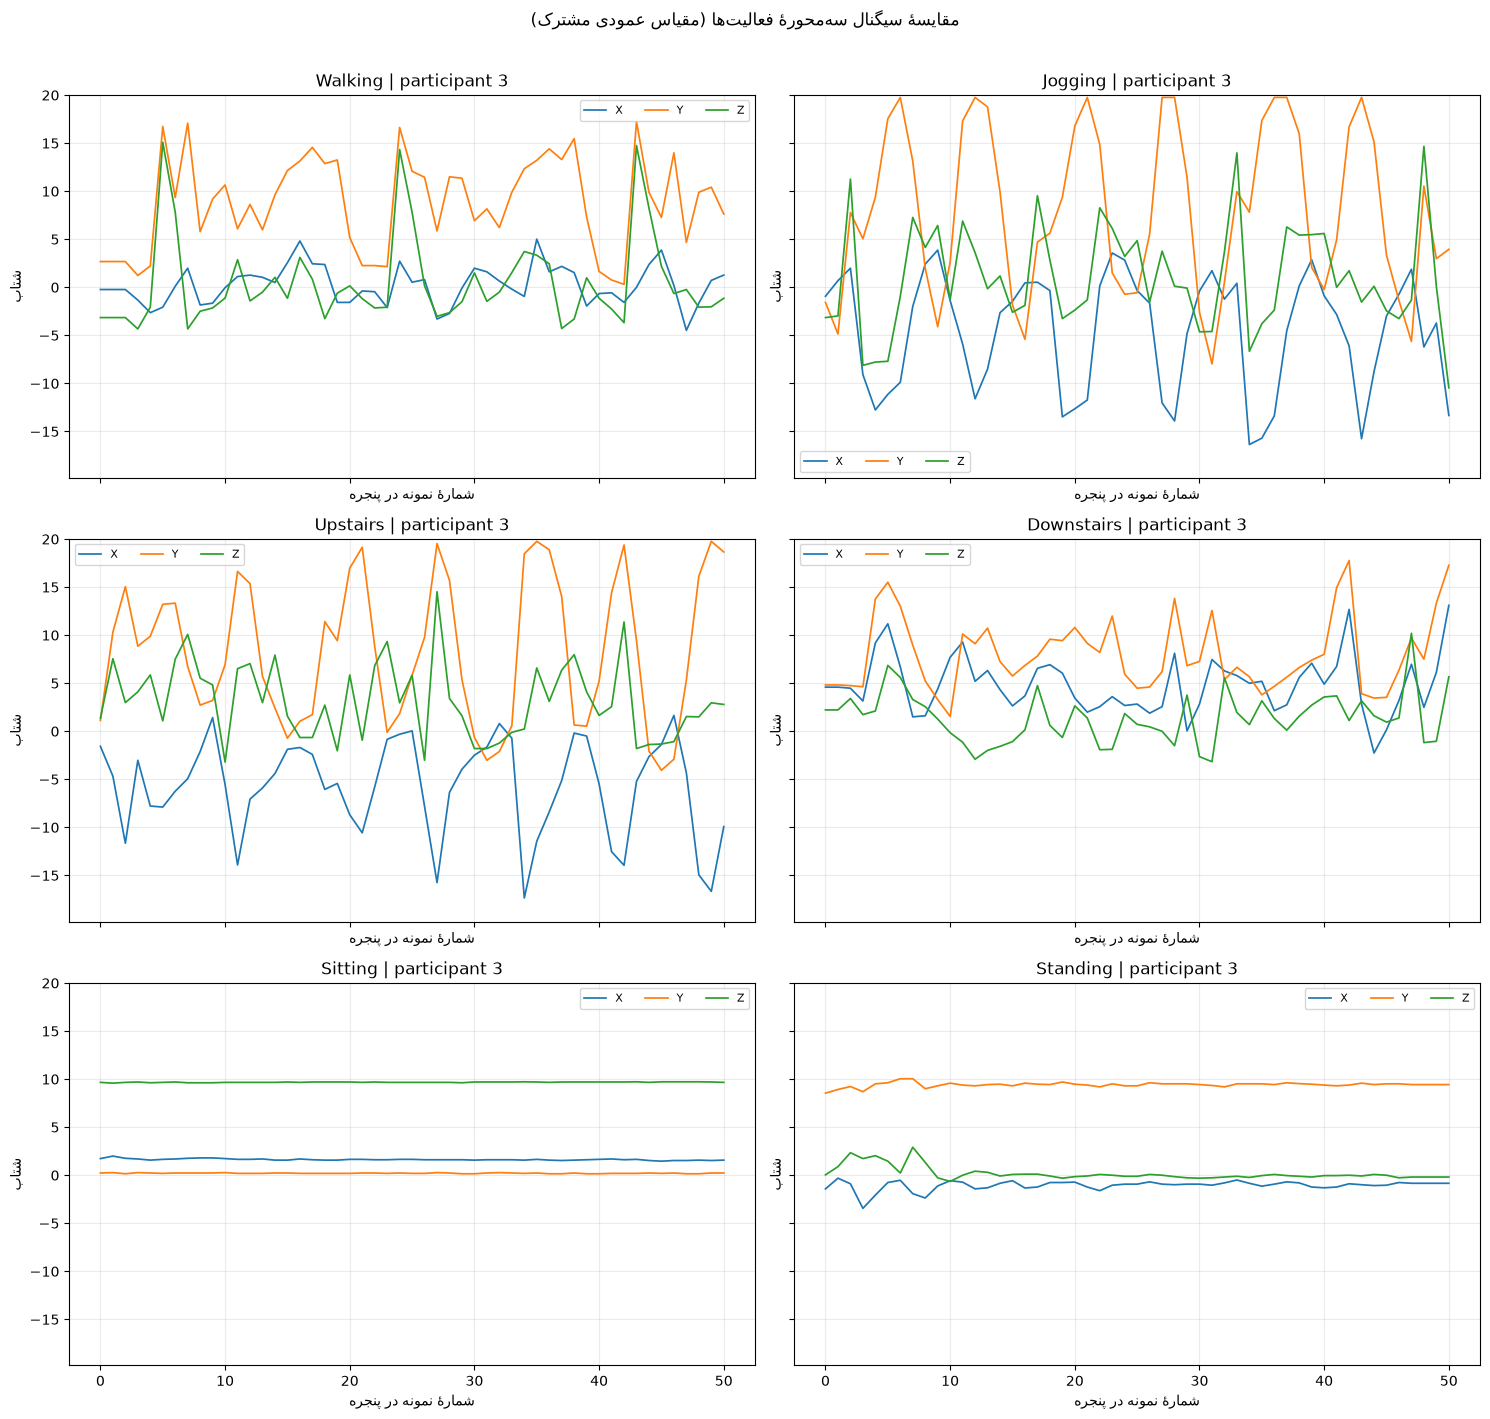

شرکت‌کنندهٔ استفاده‌شده برای هر فعالیت:


,user_id
Walking,3
Jogging,3
Upstairs,3
Downstairs,3
Sitting,3
Standing,3


In [30]:
WINDOW_SIZE, STEP = 51, 26
X_windows, meta = make_windows(data, window_size=WINDOW_SIZE, step=STEP)
if len(meta) == 0:
    raise RuntimeError("هیچ پنجره‌ای ساخته نشد؛ فایل و طول قطعات فعالیت را بررسی کنید.")

# یک شرکت‌کنندهٔ مشترک را در صورت وجود انتخاب می‌کنیم تا تفاوت فعالیت‌ها با اثر تفاوت فردی مخلوط نشود.
users_per_activity = {
    activity: set(meta.loc[meta.activity == activity, "user_id"].unique())
    for activity in ACTIVITY_ORDER
}
available_user_sets = [users_per_activity[a] for a in ACTIVITY_ORDER if users_per_activity[a]]
common_users = set.intersection(*available_user_sets) if len(available_user_sets) == len(ACTIVITY_ORDER) else set()
common_user = sorted(common_users)[0] if common_users else None
print("شرکت‌کنندهٔ مشترک برای هر شش فعالیت:", common_user)

chosen = {}
chosen_users = {}
for activity in ACTIVITY_ORDER:
    candidates = meta.index[meta.activity == activity].tolist()
    if not candidates:
        chosen[activity] = None
        chosen_users[activity] = None
        continue
    if common_user is not None:
        same_user = meta.index[(meta.activity == activity) & (meta.user_id == common_user)].tolist()
        idx = same_user[0] if same_user else candidates[0]
    else:
        idx = candidates[0]
    chosen[activity] = X_windows[idx]
    chosen_users[activity] = int(meta.loc[idx, "user_id"])

# تمام پنل‌ها از min/max کلی داده استفاده می‌کنند؛ بازهٔ عمودی به تفکیک فعالیت تغییر نمی‌کند.
y_min = float(data[AXES].min().min())
y_max = float(data[AXES].max().max())
fig, axes = plt.subplots(3, 2, figsize=(15, 14), sharex=True, sharey=True)
for ax, activity in zip(axes.flat, ACTIVITY_ORDER):
    signal = chosen[activity]
    if signal is None:
        ax.text(0.5, 0.5, "پنجرهٔ کافی موجود نیست", ha="center", va="center")
        ax.set_title(activity)
        ax.set_ylim(y_min, y_max)
        continue
    for axis_index, axis_name in enumerate(AXES):
        ax.plot(signal[:, axis_index], label=axis_name, linewidth=1.25)
    ax.set_title(f"{activity} | participant {chosen_users[activity]}")
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("شمارهٔ نمونه در پنجره")
    ax.set_ylabel("شتاب")
    ax.legend(ncol=3, fontsize=8)
fig.suptitle("مقایسهٔ سیگنال سه‌محورهٔ فعالیت‌ها (مقیاس عمودی مشترک)", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_six_activity_signals.png", dpi=160, bbox_inches="tight")
plt.show()

print("شرکت‌کنندهٔ استفاده‌شده برای هر فعالیت:")
display(pd.Series(chosen_users, name="user_id").to_frame())

**محدودیت تحلیل:** لازم به ذکر است که نمودارهای ارائه‌شده بر اساس یک پنجره از هر فعالیت برای شرکت‌کننده شماره ۳ رسم شده‌اند. بنابراین، الگوهای مشاهده‌شده لزوماً بیانگر رفتار حرکتی تمام شرکت‌کنندگان نیستند و صرفاً با هدف مقایسه بصری سیگنال فعالیت‌های مختلف ارائه شده‌اند.

### تفسیر و تحلیل سیگنال فعالیت‌ها

- فعالیت‌های پویا مانند راه‌رفتن (Walking) و دویدن (Jogging)، در مقایسه با فعالیت‌های کم‌تحرک مانند نشستن (Sitting) و ایستادن (Standing)، معمولاً نوسانات بیشتری در سیگنال‌های شتاب‌سنج ایجاد می‌کنند.

- فعالیت دویدن معمولاً با تغییرات شدیدتر و الگوهای حرکتی پویاتری نسبت به راه‌رفتن همراه است. بااین‌حال، عواملی مانند سرعت حرکت، تفاوت‌های فردی و کوتاه بودن بازه زمانی پنجره می‌توانند باعث هم‌پوشانی الگوهای این دو فعالیت شوند.

- فعالیت‌های نشستن و ایستادن از نظر میزان تحرک شباهت زیادی به یکدیگر دارند. ازاین‌رو، تشخیص دقیق آن‌ها صرفاً بر اساس یک پنجره کوتاه از داده‌ها ممکن است دشوار باشد. همچنین، وضعیت قرارگیری تلفن همراه و جهت مؤلفه گرانش می‌توانند بر شکل سیگنال‌ها تأثیر بگذارند.

- هر پنجره با طول ۵۱ نمونه، تقریباً ۲٫۵۵ ثانیه از فعالیت فرد را پوشش می‌دهد. این بازه زمانی ممکن است برای ثبت بخشی از الگوی حرکتی کافی باشد، اما در برخی موارد، به‌ویژه هنگام تغییر فعالیت یا حرکات متغیر، اطلاعات کاملی در اختیار مدل قرار ندهد.

در مجموع، نمودارهای سیگنال امکان مشاهده تفاوت‌های اولیه میان فعالیت‌ها را فراهم می‌کنند؛ بااین‌حال، ارزیابی دقیق قابلیت تفکیک این فعالیت‌ها نیازمند بررسی نتایج استخراج ویژگی‌ها و عملکرد مدل‌های یادگیری ماشین است.

## ۶. تفاوت‌های فردی: Walking برای دست‌کم سه شرکت‌کننده

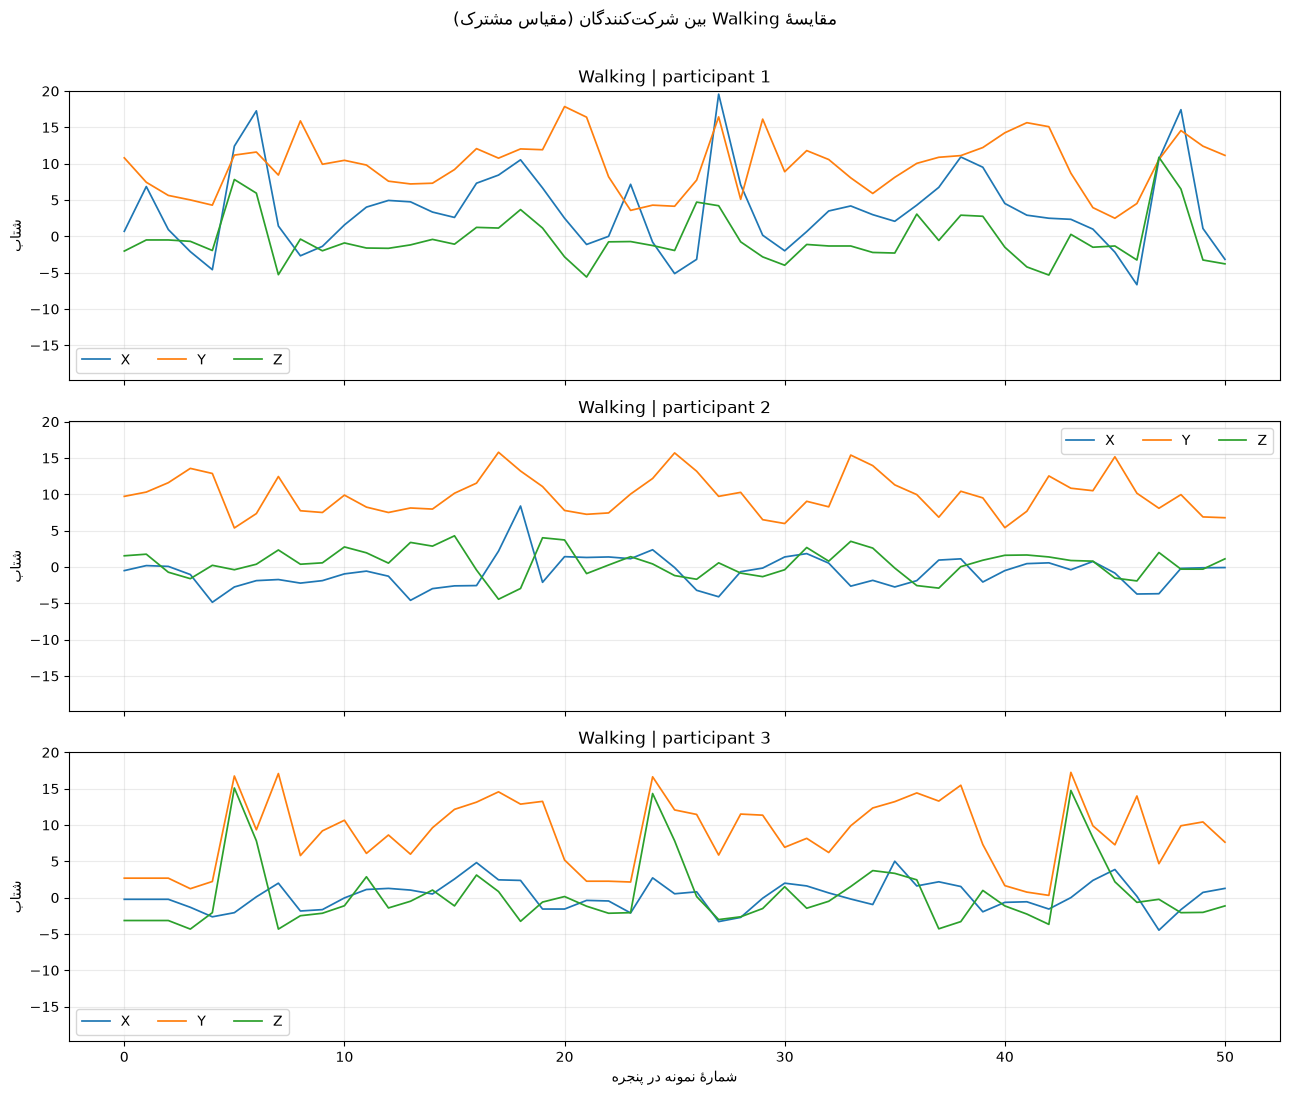

شناسه‌های استفاده‌شده: [np.int64(1), np.int64(2), np.int64(3)]


In [31]:
walking_meta = meta[meta.activity == "Walking"].copy()
walking_users = sorted(walking_meta.user_id.unique())
if len(walking_users) < 3:
    warnings.warn("کمتر از سه شرکت‌کننده برای Walking پنجرهٔ کامل دارند.")
selected_users = walking_users[:3]

fig, axes = plt.subplots(len(selected_users), 1, figsize=(13, 3.6 * max(1, len(selected_users))), sharex=True, sharey=True)
if len(selected_users) == 1:
    axes = [axes]
for ax, user in zip(axes, selected_users):
    idx = walking_meta.index[walking_meta.user_id == user][0]
    signal = X_windows[idx]
    for j, axis_name in enumerate(AXES):
        ax.plot(signal[:, j], label=axis_name, linewidth=1.25)
    ax.set_title(f"Walking | participant {user}")
    ax.set_ylim(y_min, y_max)
    ax.set_ylabel("شتاب")
    ax.legend(ncol=3)
axes[-1].set_xlabel("شمارهٔ نمونه در پنجره")
fig.suptitle("مقایسهٔ Walking بین شرکت‌کنندگان (مقیاس مشترک)", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_walking_subject_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
print("شناسه‌های استفاده‌شده:", selected_users)

### تفسیر و تحلیل تفاوت‌های فردی

با وجود یکسان بودن نوع فعالیت (Walking)، نمودارها تفاوت‌هایی را در شکل موج و دامنه تغییرات سیگنال‌های شتاب‌سنج سه شرکت‌کننده نشان می‌دهند. برای مثال، در سیگنال شرکت‌کننده اول نوسانات قابل‌توجهی در محور X مشاهده می‌شود، درحالی‌که سیگنال همین محور برای شرکت‌کننده دوم عمدتاً در محدوده نزدیک به صفر قرار دارد. همچنین، در سیگنال شرکت‌کننده سوم، محور Z دارای چند قله مشخص و تغییرات مقطعی نسبتاً شدید است. این مشاهدات نشان می‌دهند که حتی هنگام انجام یک فعالیت یکسان، الگوهای ثبت‌شده توسط شتاب‌سنج می‌توانند بین افراد متفاوت باشند.

این تفاوت‌ها ممکن است تحت تأثیر عواملی مانند سرعت حرکت، طول گام، شیوه راه‌رفتن، ویژگی‌های فردی و محل یا جهت قرارگیری تلفن همراه باشند. بنابراین، مدل یادگیری ماشین باید علاوه بر شناسایی الگوهای مربوط به هر فعالیت، توانایی تعمیم به تفاوت‌های فردی را نیز داشته باشد.

ازاین‌رو، در تقسیم داده‌ها به مجموعه‌های آموزش، اعتبارسنجی و آزمون، شناسه شرکت‌کننده باید مورد توجه قرار گیرد. استفاده از تقسیم‌بندی مبتنی بر شرکت‌کننده (Subject-wise Split) کمک می‌کند عملکرد مدل روی افراد دیده‌نشده ارزیابی شود و احتمال وابستگی بیش از حد مدل به الگوهای حرکتی افراد حاضر در داده‌های آموزش کاهش یابد.

## ۷. مقایسهٔ دو جفت فعالیت مشابه

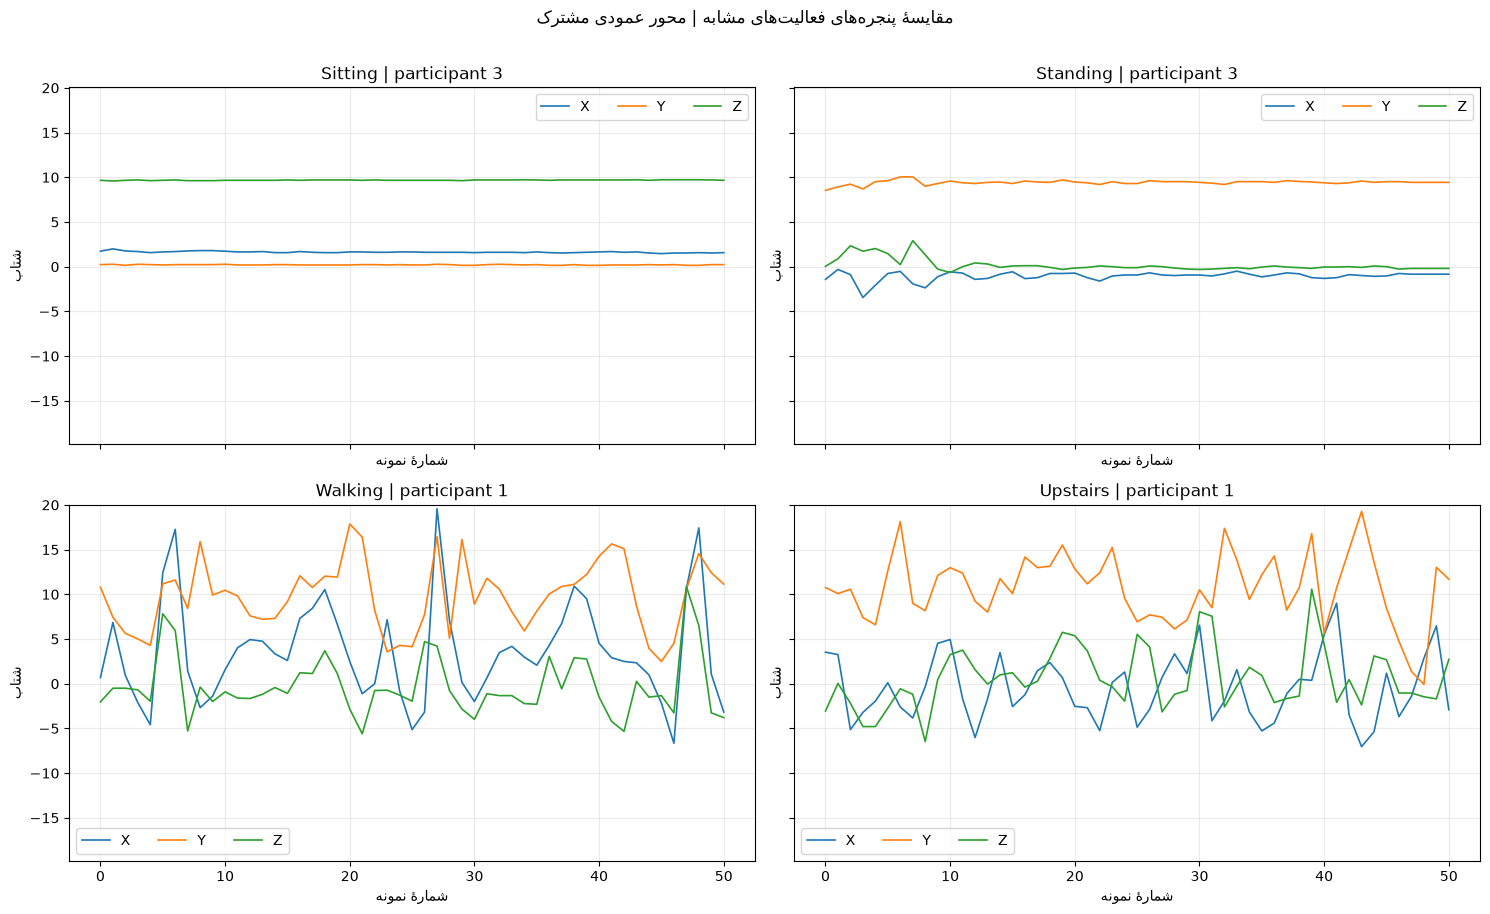

In [32]:
def get_first_window(activity, preferred_user=None):
    mask = meta.activity.eq(activity)
    if preferred_user is not None:
        same = meta.index[mask & meta.user_id.eq(preferred_user)]
        if len(same):
            return X_windows[same[0]], int(preferred_user)
    idx = meta.index[mask]
    if len(idx) == 0:
        return None, None
    i = idx[0]
    return X_windows[i], int(meta.loc[i, "user_id"])

pairs = [("Sitting", "Standing"), ("Walking", "Upstairs")]
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
for row, (a1, a2) in enumerate(pairs):
    available1 = set(meta.loc[meta.activity == a1, "user_id"])
    available2 = set(meta.loc[meta.activity == a2, "user_id"])
    shared = sorted(available1 & available2)
    preferred = shared[0] if shared else None
    for col, activity in enumerate((a1, a2)):
        sig, user = get_first_window(activity, preferred)
        ax = axes[row, col]
        if sig is None:
            ax.text(0.5, 0.5, "پنجرهٔ کافی موجود نیست", ha="center", va="center")
            ax.set_axis_off()
            continue
        for j, axis_name in enumerate(AXES):
            ax.plot(sig[:, j], label=axis_name, linewidth=1.2)
        ax.set_title(f"{activity} | participant {user}")
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel("شمارهٔ نمونه")
        ax.set_ylabel("شتاب")
        ax.legend(ncol=3)
plt.suptitle("مقایسهٔ پنجره‌های فعالیت‌های مشابه | محور عمودی مشترک", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_similar_activity_pairs.png", dpi=160, bbox_inches="tight")
plt.show()

### تفسیر و تحلیل مقایسه فعالیت‌های مشابه

در مقایسه فعالیت‌های نشستن و ایستادن، مشاهده می‌شود که سیگنال‌های هر دو فعالیت در بیشتر طول پنجره تغییرات محدودی دارند. بااین‌حال، تفاوت‌هایی در مقدار و نحوه تغییر سیگنال‌های سه محور شتاب‌سنج دیده می‌شود. این تفاوت‌ها می‌توانند به وضعیت بدن و جهت قرارگیری تلفن همراه هنگام ثبت داده‌ها مربوط باشند.

در مقایسه راه‌رفتن و بالا رفتن از پله، نوسانات سیگنال‌ها بیشتر است. هر دو فعالیت با حرکت بدن همراه هستند، اما شکل موج و دامنه تغییرات در محورهای مختلف تفاوت دارد. این تفاوت‌ها ممکن است بازتابی از تفاوت در شیوه حرکت و شدت فعالیت باشند.

در مجموع، نمودارها نشان می‌دهند که فعالیت‌های مشابه می‌توانند در برخی ویژگی‌های سیگنال به یکدیگر نزدیک باشند، اما در عین حال تفاوت‌هایی نیز داشته باشند. این موضوع تشخیص و تفکیک چنین فعالیت‌هایی را برای مدل یادگیری ماشین دشوارتر می‌کند و اهمیت استخراج ویژگی‌های مناسب را نشان می‌دهد.

**محدودیت تحلیل:** در این مقایسه، برای هر فعالیت تنها یک پنجره شامل ۵۱ نمونه بررسی شده است. بنابراین، نتایج صرفاً بیانگر مشاهدات اولیه از این پنجره‌ها هستند و نمی‌توان آن‌ها را به تمام افراد یا همه حالت‌های انجام فعالیت تعمیم داد.

## ۸. پیشنهاد حداقل سه ویژگی برای PT2



برای بهبود تشخیص فعالیت‌های انسانی در مرحله دوم پروژه، می‌توان ویژگی‌های آماری و حرکتی مختلفی را از پنجره‌های سیگنال شتاب‌سنج استخراج کرد. ویژگی‌های زیر به‌عنوان پیشنهاد اولیه در نظر گرفته می‌شوند:

| ویژگی پیشنهادی | چه چیزی را توصیف می‌کند؟ | دلیل انتخاب و کاربرد احتمالی | میزان وابستگی به فرد |
|---|---|---|---|
| انحراف معیار هر محور | میزان پراکندگی و نوسان مقادیر شتاب در هر محور | فعالیت‌های پویا معمولاً نوسانات بیشتری نسبت به فعالیت‌های کم‌تحرک ایجاد می‌کنند؛ بنابراین این ویژگی می‌تواند به تفکیک فعالیت‌ها کمک کند. | نسبتاً زیاد؛ سرعت حرکت و جهت قرارگیری تلفن همراه بر آن اثر می‌گذارند. |
| میانگین و انحراف معیار اندازه بردار شتاب | مقدار متوسط و میزان تغییرات شدت کلی شتاب، با تأثیر کمتر از چرخش دستگاه بر مؤلفه‌های جداگانه | می‌تواند برای مقایسه شدت حرکت و تفکیک فعالیت‌هایی مانند راه‌رفتن، دویدن و حالت‌های کم‌تحرک مفید باشد. | متوسط؛ محل قرارگیری تلفن همراه و الگوی حرکت فرد همچنان مؤثر هستند. |
| مقدار مؤثر سیگنال (RMS) | سطح کلی سیگنال در یک پنجره و میزان شدت آن | می‌تواند تفاوت سطح فعالیت و شدت حرکات را نشان دهد و در تفکیک فعالیت‌های پویا از کم‌تحرک مفید باشد. | نسبتاً زیاد؛ سرعت حرکت، شیوه گام‌برداشتن و محل قرارگیری تلفن همراه بر آن اثر دارند. |
| میانگین قدرمطلق تغییرات شتاب (جرک) | میزان و شدت تغییرات شتاب در طول زمان | می‌تواند اطلاعاتی درباره تغییرات سریع حرکت و ضربه‌های ناشی از گام‌برداشتن فراهم کند و در تمایز فعالیت‌های حرکتی مشابه مفید باشد. | نسبتاً زیاد؛ شیوه حرکت فرد و نرخ نمونه‌برداری بر آن تأثیر دارند. |

**جمع‌بندی:** ویژگی‌های پیشنهادی می‌توانند جنبه‌های متفاوتی از سیگنال، از جمله میزان نوسان، شدت حرکت و سرعت تغییرات شتاب را توصیف کنند. ترکیب این ویژگی‌ها ممکن است به تفکیک بهتر فعالیت‌های مشابه کمک کند. بااین‌حال، میزان مفید بودن هر ویژگی باید در مرحله دوم پروژه و از طریق استخراج، تحلیل و ارزیابی مدل بررسی شود.

لازم به ذکر است که در پروژه حاضر، این موارد صرفاً به‌عنوان ویژگی‌های پیشنهادی معرفی می‌شوند و استخراج و ارزیابی عملی آن‌ها به مرحله دوم پروژه موکول می‌شود.

## ۹. پنجره‌بندی زمانی (Windowing)

### توضیح مفهومی پنجره‌بندی

هر نمونه خام، یک اندازه‌گیری از شتاب را در یک لحظه مشخص ثبت می‌کند و به‌تنهایی اطلاعات محدودی درباره ریتم و الگوی زمانی حرکت در اختیار می‌گذارد. در روش پنجره‌بندی، ۵۱ نمونه متوالی از سه محور شتاب‌سنج در قالب یک آرایه چندبعدی قرار می‌گیرند تا بخشی از الگوی زمانی فعالیت ثبت شود.

گام حرکت پنجره برابر با ۲۶ نمونه است؛ یعنی پنجره بعدی از نمونه بیست‌وششم پس از شروع پنجره قبلی آغاز می‌شود. در نتیجه، دو پنجره متوالی ۲۵ نمونه مشترک دارند. این هم‌پوشانی ضمن افزایش تعداد پنجره‌های قابل استفاده، احتمال از دست رفتن بخشی از تغییرات سیگنال در مرز پنجره‌ها را کاهش می‌دهد. بااین‌حال، پنجره‌های حاصل به دلیل داشتن نمونه‌های مشترک، مستقل از یکدیگر نیستند و می‌توانند هم‌بستگی زیادی داشته باشند. بنابراین، تقسیم تصادفی پنجره‌ها میان مجموعه‌های آموزش و آزمون ممکن است باعث نشت اطلاعات و برآورد خوش‌بینانه از عملکرد مدل شود.

همچنین، اگر یک پنجره شامل نمونه‌هایی از دو فعالیت متفاوت باشد، اختصاص یک برچسب واحد به آن می‌تواند مبهم باشد. ازاین‌رو، در پیاده‌سازی حاضر، پنجره‌ها به‌گونه‌ای ساخته شده‌اند که هر پنجره فقط شامل نمونه‌های متعلق به یک شرکت‌کننده و یک فعالیت باشد.

تعداد رکوردهای خام پس از پاک‌سازی: 1086465
تعداد پنجره‌های کامل: 33126
شکل آرایهٔ ورودی پنجره‌ها: (33126, 51, 3)


,windows,percent
activity,,
Walking,14200,42.866630
Jogging,8473,25.578096
Upstairs,3978,12.008694
Downstairs,3177,9.590654
Sitting,1765,5.328141
Standing,1533,4.627785


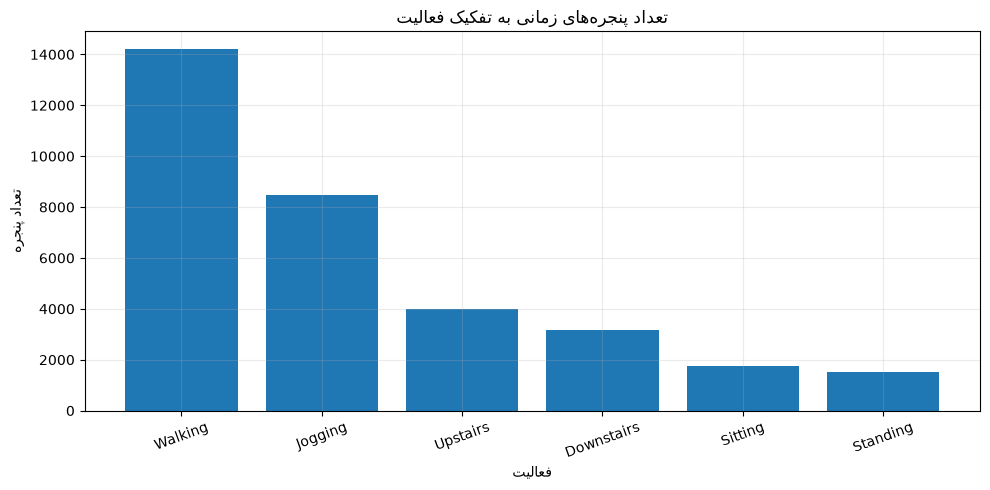

,quantity,count
0,raw records,1086465
1,windows,33126


مدت تقریبی هر پنجره: 2.55 ثانیه
هم‌پوشانی پنجره‌های متوالی: 25 نمونه = 49.01960784313726 %


In [33]:
print("تعداد رکوردهای خام پس از پاک‌سازی:", len(data))
print("تعداد پنجره‌های کامل:", len(meta))
print("شکل آرایهٔ ورودی پنجره‌ها:", X_windows.shape)

window_counts = (
    meta["activity"].value_counts()
    .reindex(ACTIVITY_ORDER, fill_value=0)
    .rename("windows")
    .to_frame()
)
window_counts["percent"] = 100 * window_counts["windows"] / max(len(meta), 1)
display(window_counts)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(window_counts.index, window_counts["windows"])
ax.set(title="تعداد پنجره‌های زمانی به تفکیک فعالیت", xlabel="فعالیت", ylabel="تعداد پنجره")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_window_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

raw_vs_windows = pd.DataFrame({
    "quantity": ["raw records", "windows"],
    "count": [len(data), len(meta)]
})
display(raw_vs_windows)

# کنترل خودکار: هر پنجره فقط به یک فرد و یک فعالیت تعلق دارد.
assert meta["user_id"].notna().all() and meta["activity"].notna().all()
assert X_windows.shape[1:] == (51, 3)
print("مدت تقریبی هر پنجره:", 51 / 20, "ثانیه")
print("هم‌پوشانی پنجره‌های متوالی:", 51 - 26, "نمونه =", 100 * (51 - 26) / 51, "%")

#### کنترل صحت پنجره‌بندی

In [34]:
# کنترل یکسان بودن شرکت‌کننده و فعالیت در هر پنجره
assert len(X_windows) == len(meta)

assert meta["user_id"].notna().all()
assert meta["activity"].notna().all()

assert X_windows.shape[1:] == (51, 3)
assert meta["window_size"].eq(51).all()

# کنترل یکتایی برچسب فعالیت در هر قطعه
segment_check = (
    data.sort_values(["user_id", "timestamp"])
    .groupby("user_id")["activity"]
    .apply(lambda s: s.ne(s.shift()).cumsum())
)

print("تعداد پنجره‌ها:", len(meta))
print("تعداد افراد:", meta["user_id"].nunique())
print("تعداد فعالیت‌ها:", meta["activity"].nunique())
print("کنترل ابعاد و مشخصات پنجره‌ها: موفق")
print("کنترل‌های اولیه: موفق")

تعداد پنجره‌ها: 33126
تعداد افراد: 36
تعداد فعالیت‌ها: 6
کنترل ابعاد و مشخصات پنجره‌ها: موفق
کنترل‌های اولیه: موفق


در مجموع، با اجرای فرایند پنجره‌بندی، ۳۳٬۱۲۶ پنجره با طول ۵۱ نمونه و هم‌پوشانی تقریبی ۴۹ درصد استخراج شد. این پنجره‌ها به‌عنوان ورودی مراحل بعدی پروژه مورد استفاده قرار می‌گیرند. همچنین، با توجه به عدم‌توازن تعداد پنجره‌های فعالیت‌های مختلف و هم‌پوشانی پنجره‌های متوالی، این ملاحظات در مراحل تقسیم داده‌ها و ارزیابی مدل در نظر گرفته خواهند شد.

## ۱۰. تفکیک آموزش، اعتبارسنجی و آزمون بر اساس شرکت‌کننده

In [35]:
import importlib
import pt1_utils

importlib.reload(pt1_utils)

subject_wise_split = pt1_utils.subject_wise_split
split_summary = pt1_utils.split_summary

print("توابع تقسیم داده با موفقیت بارگذاری شدند.")

توابع تقسیم داده با موفقیت بارگذاری شدند.


### چرا تقسیم تصادفی پنجره‌ها مناسب نیست؟

پنجره‌های متوالی به دلیل هم‌پوشانی، ممکن است ۲۵ نمونه خام مشترک داشته باشند. حتی در پنجره‌های بدون هم‌پوشانی نیز داده‌های مربوط به یک شرکت‌کننده می‌توانند از نظر جهت قرارگیری تلفن همراه، دامنه حرکات و الگوهای بدنی شباهت زیادی به یکدیگر داشته باشند.

اگر پنجره‌های یک شرکت‌کننده به‌صورت تصادفی میان مجموعه‌های آموزش و آزمون تقسیم شوند، مدل ممکن است به‌جای یادگیری الگوهای عمومی فعالیت‌ها، تا حدی ویژگی‌های خاص آن فرد را یاد بگیرد. در نتیجه، عملکرد ارزیابی‌شده روی مجموعه آزمون ممکن است بیش از مقدار واقعی آن برای افراد جدید باشد.

بنابراین، استفاده از روش تقسیم‌بندی مبتنی بر شرکت‌کننده (Subject-wise Split) امکان ارزیابی واقع‌بینانه‌تری از توانایی مدل در شناسایی فعالیت‌های افراد دیده‌نشده را فراهم می‌کند.

In [36]:
y = meta["activity"].to_numpy()
groups = meta["user_id"].to_numpy()
train_idx, val_idx, test_idx, split_info = subject_wise_split(y, groups)

split_indices = {"train": train_idx, "validation": val_idx, "test": test_idx}
train_users = set(meta.iloc[train_idx].user_id)
val_users = set(meta.iloc[val_idx].user_id)
test_users = set(meta.iloc[test_idx].user_id)

assert train_users.isdisjoint(val_users)
assert train_users.isdisjoint(test_users)
assert val_users.isdisjoint(test_users)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(meta)

print("اطلاعات الگوریتم تقسیم:")
display(pd.Series(split_info, name="value").to_frame())
print("شناسه‌های آموزش:", sorted(train_users))
print("شناسه‌های اعتبارسنجی:", sorted(val_users))
print("شناسه‌های آزمون:", sorted(test_users))

split_table = split_summary(meta, split_indices)
display(split_table)

# توزیع نسبی فعالیت‌ها در هر مجموعه
split_distribution = split_table[[f"{a}_windows" for a in ACTIVITY_ORDER]].div(
    split_table["windows"], axis=0
)
display((split_distribution * 100).round(1).astype(str) + "%")

print("اشتراک شرکت‌کنندگان بین train/validation:", train_users & val_users)
print("اشتراک شرکت‌کنندگان بین train/test:", train_users & test_users)
print("اشتراک شرکت‌کنندگان بین validation/test:", val_users & test_users)

split_table.to_csv(OUTPUT_DIR / "split_summary.csv", encoding="utf-8-sig")

اطلاعات الگوریتم تقسیم:


,value
random_state,0
validation_fold,1
test_fold,3
score,0.000715
class_coverage,"{'train': ['Downstairs', 'Jogging', 'Sitting',..."
missing_classes_in_any_split,False


شناسه‌های آموزش: [1, 2, 5, 7, 9, 11, 12, 13, 15, 17, 19, 20, 21, 22, 24, 25, 28, 29, 30, 31, 34, 35]
شناسه‌های اعتبارسنجی: [3, 14, 16, 23, 32, 33, 36]
شناسه‌های آزمون: [4, 6, 8, 10, 18, 26, 27]


,participants,windows,Walking_windows,Jogging_windows,Upstairs_windows,Downstairs_windows,Sitting_windows,Standing_windows
split,,,,,,,,
train,22,19959,8482,5234,2337,1873,1106,927
validation,7,6879,2786,1699,1018,656,418,302
test,7,6288,2932,1540,623,648,241,304


,Walking_windows,Jogging_windows,Upstairs_windows,Downstairs_windows,Sitting_windows,Standing_windows
split,,,,,,
train,42.5%,26.2%,11.7%,9.4%,5.5%,4.6%
validation,40.5%,24.7%,14.8%,9.5%,6.1%,4.4%
test,46.6%,24.5%,9.9%,10.3%,3.8%,4.8%


اشتراک شرکت‌کنندگان بین train/validation: set()
اشتراک شرکت‌کنندگان بین train/test: set()
اشتراک شرکت‌کنندگان بین validation/test: set()


### تحلیل و ارزیابی تقسیم داده‌ها

به‌منظور ارزیابی توانایی تعمیم مدل به افراد جدید و جلوگیری از نشت اطلاعات، تقسیم داده‌ها به روش مبتنی بر شرکت‌کننده انجام شد. در این روش، پنجره‌های متعلق به هر فرد به‌طور کامل در یکی از مجموعه‌های آموزش، اعتبارسنجی یا آزمون قرار گرفتند؛ بنابراین، هیچ شرکت‌کننده‌ای به‌صورت مشترک در بیش از یک مجموعه حضور ندارد.

از مجموع ۳۶ شرکت‌کننده و ۳۳٬۱۲۶ پنجره استخراج‌شده، تعداد ۲۲ شرکت‌کننده با ۱۹٬۹۵۹ پنجره به مجموعه آموزش، ۷ شرکت‌کننده با ۶٬۸۷۹ پنجره به مجموعه اعتبارسنجی و ۷ شرکت‌کننده با ۶٬۲۸۸ پنجره به مجموعه آزمون اختصاص یافتند. این تقسیم‌بندی از نظر تعداد شرکت‌کنندگان تقریباً نسبت ۶۰، ۲۰ و ۲۰ درصد را رعایت می‌کند.

بررسی توزیع فعالیت‌ها نشان داد که هر شش کلاس در هر سه مجموعه حضور دارند. اگرچه سهم نسبی فعالیت‌ها در مجموعه‌های مختلف کاملاً یکسان نیست، توزیع آن‌ها در مجموع نسبتاً نزدیک است. همچنین، کنترل‌های انجام‌شده عدم هم‌پوشانی شناسه شرکت‌کنندگان و استفاده از تمام پنجره‌ها را تأیید کردند.

در مجموع، تقسیم‌بندی مبتنی بر شرکت‌کننده امکان ارزیابی واقع‌بینانه‌تری از عملکرد مدل روی افرادی را فراهم می‌کند که در فرایند آموزش حضور نداشته‌اند. ازاین‌رو، مجموعه آزمون برای ارزیابی نهایی مدل و مجموعه اعتبارسنجی برای بررسی و انتخاب تنظیمات مدل مورد استفاده قرار خواهند گرفت.

## ۱۱. ساخت مدل پایه — Baseline Model
### انتخاب تنظیمات با استفاده از مجموعه اعتبارسنجی — Validation Set

### معرفی مدل‌های مورد استفاده

در این مرحله، به‌منظور ایجاد یک معیار اولیه برای مقایسه و بررسی توانایی تشخیص فعالیت‌های انسانی، دو مدل یادگیری ماشین مورد استفاده قرار می‌گیرند.

**۱. مدل کلاس اکثریت**

`Majority Class`

این مدل ساده‌ترین معیار پایه برای مقایسه است و همواره پرتکرارترین فعالیت در مجموعه آموزش را به‌عنوان خروجی پیش‌بینی می‌کند. هدف از استفاده از آن، بررسی این موضوع است که آیا مدل یادگیری ماشین می‌تواند عملکردی بهتر از یک پیش‌بینی ساده و مبتنی بر فراوانی کلاس‌ها داشته باشد یا خیر.

**۲. رگرسیون لجستیک**

`Logistic Regression`

این مدل یک روش یادگیری ماشین برای طبقه‌بندی است که با استفاده از ویژگی‌های استخراج‌شده از پنجره‌های زمانی، فعالیت‌های مختلف را پیش‌بینی می‌کند. عملکرد آن با بررسی چند مقدار متفاوت از پارامتر تنظیم‌گر `C` ارزیابی می‌شود تا مناسب‌ترین تنظیم بر اساس نتایج مجموعه اعتبارسنجی انتخاب شود.

In [37]:
# تنظیمات و ابزارهای موردنیاز مدل‌سازی

SEED = 42

from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("تنظیمات و ابزارهای مدل‌سازی با موفقیت آماده شدند.")

تنظیمات و ابزارهای مدل‌سازی با موفقیت آماده شدند.


In [38]:
# نمایش سادهٔ هر پنجره: الحاق سه محور در طول ۵۱ نمونه => ۱۵۳ ویژگی خام
X_flat = X_windows.reshape(len(X_windows), -1)

X_train, y_train = X_flat[train_idx], y[train_idx]
X_val, y_val = X_flat[val_idx], y[val_idx]
X_test, y_test = X_flat[test_idx], y[test_idx]

# مدل Majority Class: فقط از برچسب‌های آموزش برای تعیین کلاس اکثریت استفاده می‌شود.
majority_class = pd.Series(y_train).value_counts().idxmax()
majority_val_pred = np.repeat(majority_class, len(y_val))
majority_test_pred = np.repeat(majority_class, len(y_test))

print("کلاس اکثریت در آموزش:", majority_class)
print("Majority validation accuracy:", accuracy_score(y_val, majority_val_pred))
print("Majority validation macro-F1:", f1_score(
    y_val, majority_val_pred, labels=ACTIVITY_ORDER, average="macro", zero_division=0
))

# انتخاب C فقط روی validation؛ test در این مرحله استفاده نمی‌شود.
C_VALUES = [0.01, 0.1, 1.0, 10.0]
validation_rows = []
models = {}
for C in C_VALUES:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=C, max_iter=3000, class_weight="balanced", solver="lbfgs", random_state=SEED
        )),
    ])
    candidate.fit(X_train, y_train)
    pred_val = candidate.predict(X_val)
    val_macro_f1 = f1_score(
        y_val, pred_val, labels=ACTIVITY_ORDER, average="macro", zero_division=0
    )
    validation_rows.append({
        "C": C,
        "validation_accuracy": accuracy_score(y_val, pred_val),
        "validation_macro_f1": val_macro_f1,
    })
    models[C] = candidate

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(validation_results)
best_C = float(validation_results.iloc[0]["C"])
best_model = models[best_C]
print("بهترین C بر اساس Macro-F1 اعتبارسنجی:", best_C)

کلاس اکثریت در آموزش: Walking
Majority validation accuracy: 0.40500072684983285
Majority validation macro-F1: 0.09608553198827384


,C,validation_accuracy,validation_macro_f1
0,1.00,0.334351,0.367384
1,0.10,0.334351,0.367326
2,10.00,0.334060,0.367223
3,0.01,0.333769,0.365484


بهترین C بر اساس Macro-F1 اعتبارسنجی: 1.0


### تحلیل و جمع‌بندی نتایج

نتایج ارزیابی مدل کلاس اکثریت نشان می‌دهد که این مدل با دقت ۴۰٫۵۰ درصد، عملکرد اولیه قابل‌توجهی از نظر دقت دارد؛ اما امتیاز Macro-F1 آن برابر با ۰٫۰۹۶۱ است. دلیل پایین بودن این امتیاز آن است که مدل همواره فعالیت راه‌رفتن را پیش‌بینی می‌کند و در شناسایی سایر فعالیت‌ها توانایی مناسبی ندارد.

در مقابل، مدل رگرسیون لجستیک توانسته است با امتیاز Macro-F1 حدود ۰٫۳۶۷۴، عملکرد متوازن‌تری در شناسایی فعالیت‌های مختلف ارائه دهد. بررسی مقادیر مختلف پارامتر `C` نیز نشان داد که مقدار ۱٫۰ با کسب بالاترین امتیاز Macro-F1 در مجموعه اعتبارسنجی، مناسب‌ترین تنظیم در میان مقادیر آزمایش‌شده است.

بنابراین، مدل رگرسیون لجستیک با مقدار `C=1.0` برای ارزیابی نهایی انتخاب شد. با توجه به اینکه انتخاب مدل بر اساس مجموعه اعتبارسنجی انجام شده است، ارزیابی عملکرد نهایی آن روی مجموعه آزمون در مرحله بعد صورت خواهد گرفت.

### بررسی مدل انتخاب‌شده

In [39]:
print("متغیر best_model تعریف شده است:", "best_model" in globals())
print("متغیر models تعریف شده است:", "models" in globals())

متغیر best_model تعریف شده است: True
متغیر models تعریف شده است: True


In [40]:
print("مدل انتخاب‌شده:")
print(best_model)

print("\nمقدار C:")
print(best_model.named_steps["classifier"].C)

مدل انتخاب‌شده:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=3000,
                                    random_state=42))])

مقدار C:
1.0


## ۱۲. ارزیابی نهایی روی Test و ماتریس درهم‌ریختگی

,accuracy,macro_f1
model,,
MajorityClass,0.466285,0.106001
LogisticRegression,0.472805,0.410829


,precision,recall,f1-score,support
Walking,0.703297,0.545703,0.614557,2932.0
Jogging,0.822394,0.553247,0.661491,1540.0
Upstairs,0.122600,0.133226,0.127692,623.0
Downstairs,0.137876,0.134259,0.136044,648.0
Sitting,0.955224,0.531120,0.682667,241.0
Standing,0.145277,0.733553,0.242523,304.0


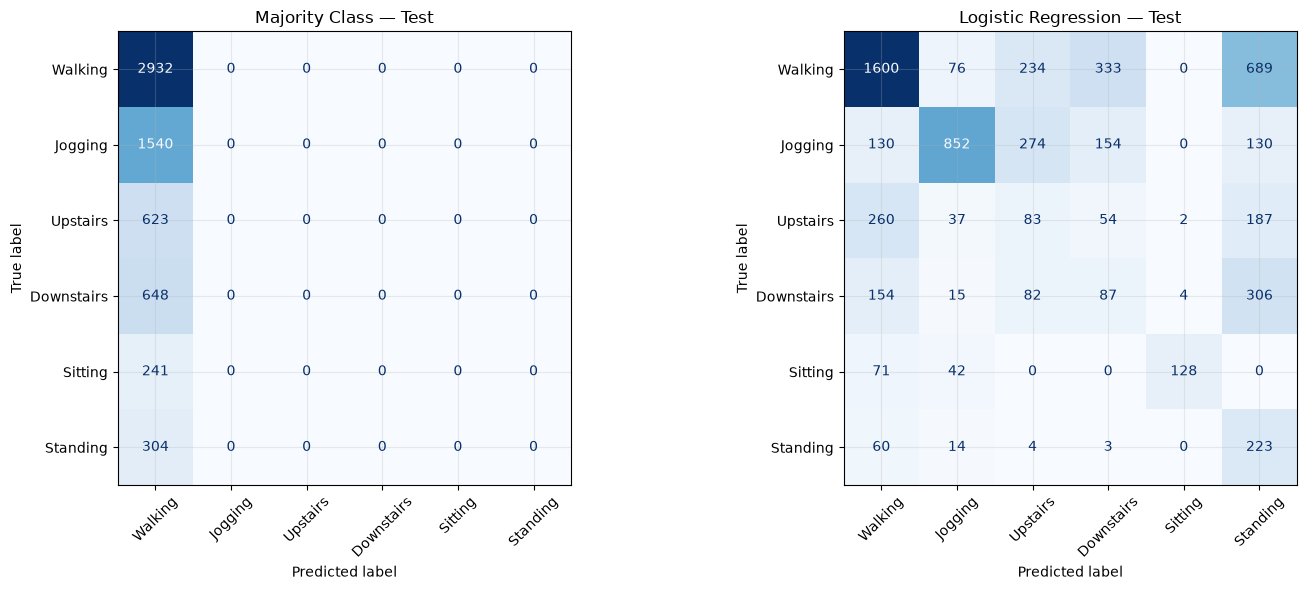

Train accuracy: 0.39786562453028707
Test accuracy: 0.47280534351145037
Train-Test accuracy gap: -0.0749397189811633
Test macro-F1: 0.4108289798094846


In [42]:
# فقط اکنون، پس از انتخاب C، از test برای ارزیابی نهایی استفاده می‌کنیم.
model_test_pred = best_model.predict(X_test)

model_report = classification_report(
    y_test, model_test_pred,
    labels=ACTIVITY_ORDER,
    output_dict=True,
    zero_division=0,
)
model_metrics = {
    "model": "LogisticRegression",
    "accuracy": accuracy_score(y_test, model_test_pred),
    "macro_f1": f1_score(y_test, model_test_pred, labels=ACTIVITY_ORDER,
                          average="macro", zero_division=0),
}
majority_metrics = {
    "model": "MajorityClass",
    "accuracy": accuracy_score(y_test, majority_test_pred),
    "macro_f1": f1_score(y_test, majority_test_pred, labels=ACTIVITY_ORDER,
                          average="macro", zero_division=0),
}
comparison = pd.DataFrame([majority_metrics, model_metrics]).set_index("model")
display(comparison)

per_class = pd.DataFrame(model_report).T.loc[ACTIVITY_ORDER, ["precision", "recall", "f1-score", "support"]]
display(per_class)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, majority_test_pred, labels=ACTIVITY_ORDER,
    display_labels=ACTIVITY_ORDER, xticks_rotation=45,
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Majority Class — Test")
ConfusionMatrixDisplay.from_predictions(
    y_test, model_test_pred, labels=ACTIVITY_ORDER,
    display_labels=ACTIVITY_ORDER, xticks_rotation=45,
    cmap="Blues", colorbar=False, ax=axes[1]
)
axes[1].set_title("Logistic Regression — Test")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

comparison.to_csv(OUTPUT_DIR / "test_metrics.csv", encoding="utf-8-sig")
per_class.to_csv(OUTPUT_DIR / "per_class_metrics.csv", encoding="utf-8-sig")
validation_results.to_csv(OUTPUT_DIR / "validation_tuning.csv", index=False, encoding="utf-8-sig")

# فاصلهٔ عملکرد آموزش و آزمون به‌عنوان یک نشانهٔ اولیه برای بررسی بیش‌برازش
train_pred = best_model.predict(X_train)
print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy:", model_metrics["accuracy"])
print("Train-Test accuracy gap:", accuracy_score(y_train, train_pred) - model_metrics["accuracy"])
print("Test macro-F1:", model_metrics["macro_f1"])

### چرا معیار ارزیابی Macro-F1 اهمیت دارد؟

معیار دقت کلی، نسبت پیش‌بینی‌های صحیح به کل نمونه‌ها را نشان می‌دهد؛ بااین‌حال، در مجموعه‌داده‌های نامتوازن ممکن است تحت تأثیر کلاس‌های پرتعداد قرار گیرد و تصویر کاملی از عملکرد مدل ارائه نکند.

در مقابل، معیار زیر ابتدا امتیاز F1 را برای هر کلاس به‌صورت جداگانه محاسبه می‌کند و سپس میانگین ساده این امتیازها را به دست می‌آورد:

`Macro-F1`

به این ترتیب، هر شش فعالیت وزن یکسانی در ارزیابی نهایی دارند؛ صرف‌نظر از تعداد نمونه‌های هر فعالیت.

استفاده از این معیار برای مسئله حاضر اهمیت ویژه‌ای دارد؛ زیرا امکان بررسی عملکرد مدل در شناسایی فعالیت‌های کم‌نمونه را نیز فراهم می‌کند. همچنین، بررسی معیارهای زیر برای هر کلاس، در کنار ماتریس درهم‌ریختگی، به شناسایی نقاط ضعف مدل و فعالیت‌هایی که بیشتر با یکدیگر اشتباه گرفته می‌شوند کمک می‌کند.

- `Precision`
- `Recall`
- `F1-score`
- `Confusion Matrix`

## ۱۳. پاسخ به پرسش‌های تحلیلی پایانی

### ۱) چرا تشخیص فعالیت انسانی مسئله‌ای مبتنی بر داده‌های دنباله‌ای است؟

داده‌های شتاب‌سنج به‌صورت متوالی و در طول زمان ثبت می‌شوند. هر فعالیت انسانی، الگوی زمانی خاصی از تغییرات شتاب در سه محور دارد. هدف این مسئله، اختصاص یک برچسب مشخص به هر قطعه از دنبالهٔ زمانی است؛ بنابراین، تشخیص فعالیت انسانی یک مسئلهٔ طبقه‌بندی چندکلاسه با ورودی‌های دارای ساختار زمانی محسوب می‌شود.

### ۲) تفاوت دادهٔ خام و پنجرهٔ زمانی چیست؟

دادهٔ خام شامل رکوردهای متوالی شتاب‌سنج است که هر رکورد اطلاعاتی مانند شناسهٔ کاربر، نوع فعالیت، زمان ثبت و سه مؤلفهٔ شتاب را در بر می‌گیرد. در مقابل، پنجرهٔ زمانی مجموعه‌ای از ۵۱ رکورد متوالی و متعلق به یک کاربر و یک فعالیت است. هر پنجره شامل ۵۱ ردیف و سه ستون مربوط به محورهای شتاب‌سنج است و یک نمونهٔ ورودی برای فرایند مدل‌سازی فراهم می‌کند.

### ۳) مزایا و محدودیت‌های هم‌پوشانی پنجره‌های زمانی چیست؟

هم‌پوشانی پنجره‌ها باعث می‌شود بخش‌هایی از سیگنال که در نزدیکی مرز دو پنجره قرار دارند، کمتر از تحلیل حذف شوند. همچنین، تعداد پنجره‌های تولیدشده را افزایش می‌دهد و امکان بررسی پیوسته‌تر سیگنال را فراهم می‌کند.

بااین‌حال، پنجره‌های مجاور به دلیل داشتن تعدادی رکورد مشترک، کاملاً مستقل نیستند. این موضوع می‌تواند هم‌بستگی میان نمونه‌ها را افزایش دهد. در صورت تقسیم تصادفی پنجره‌ها میان مجموعه‌های آموزش و آزمون، احتمال نشت اطلاعات نیز وجود دارد؛ زیرا ممکن است بخش‌هایی از دادهٔ خام مشترک در هر دو مجموعه قرار گیرند. استفاده از تقسیم‌بندی مبتنی بر شناسهٔ کاربران، این خطر را کاهش می‌دهد.

### ۴) چرا پنجره‌های متعلق به یک فرد نباید میان مجموعه‌های آموزش و آزمون تقسیم شوند؟

الگوهای حرکتی و ویژگی‌های سیگنال شتاب‌سنج ممکن است میان افراد متفاوت باشند. اگر پنجره‌های یک فرد هم‌زمان در مجموعه‌های آموزش و آزمون قرار گیرند، مدل ممکن است ویژگی‌های خاص آن فرد را در مرحلهٔ آموزش یاد بگیرد. در نتیجه، ارزیابی به‌جای سنجش توانایی مدل در تشخیص فعالیت افراد جدید، تا حدی عملکرد آن را روی افراد مشاهده‌شده نشان می‌دهد.

به همین دلیل، در این پروژه از تقسیم‌بندی مبتنی بر شناسهٔ کاربر استفاده شده است تا هیچ فردی به‌صورت مشترک در مجموعه‌های آموزش، اعتبارسنجی و آزمون حضور نداشته باشد.

### ۵) آیا معیار دقت کلی به‌تنهایی برای ارزیابی مدل کافی است؟

خیر. در مجموعه‌داده‌های نامتوازن، معیار دقت کلی ممکن است تحت تأثیر فعالیت‌های پرتعداد قرار گیرد و عملکرد ضعیف مدل در شناسایی فعالیت‌های کم‌نمونه را پنهان کند.

برای ارزیابی جامع‌تر، در این پروژه علاوه بر دقت کلی، از معیار میانگین امتیاز اف۱، معیارهای صحت و بازخوانی و ماتریس درهم‌ریختگی نیز استفاده شده است. این معیارها امکان بررسی عملکرد مدل در هر شش فعالیت و شناسایی موارد اشتباه طبقه‌بندی‌شده را فراهم می‌کنند.

### ۶) اگر عملکرد مدل روی مجموعهٔ آزمون بسیار پایین‌تر از مجموعهٔ آموزش باشد، چه دلایلی می‌تواند داشته باشد؟

اختلاف زیاد میان عملکرد آموزش و آزمون می‌تواند نشانه‌ای از بیش‌برازش باشد. همچنین، تفاوت توزیع داده‌های کاربران، تفاوت در نحوهٔ قرارگیری تلفن همراه، شدت و سبک حرکت افراد، کمبود نمونه برای برخی فعالیت‌ها و تنظیم نامناسب پارامترهای مدل می‌توانند در کاهش عملکرد آزمون نقش داشته باشند.

در اجرای حاضر، دقت مدل رگرسیون لجستیک روی مجموعهٔ آموزش حدود ۳۹٫۸ درصد و روی مجموعهٔ آزمون حدود ۴۷٫۳ درصد بوده است. بنابراین، در نتایج فعلی کاهش دقت از آموزش به آزمون مشاهده نمی‌شود و این اختلاف به‌تنهایی نشانه‌ای از بیش‌برازش نیست. البته برای قضاوت دقیق‌تر باید معیارهای دیگر و توزیع داده‌ها نیز در نظر گرفته شوند.

### ۷) آیا عملکرد خوب مدل روی این مجموعه‌داده، عملکرد مشابه آن را در دنیای واقعی تضمین می‌کند؟

خیر. عملکرد مناسب روی یک مجموعه‌داده لزوماً به معنای عملکرد مشابه در تمام شرایط واقعی نیست. تفاوت میان کاربران، مدل دستگاه، محل قرارگیری تلفن همراه، سرعت حرکت، شرایط ثبت داده و ترکیب فعالیت‌ها می‌تواند بر عملکرد مدل تأثیر بگذارد.

تقسیم‌بندی مبتنی بر کاربران، ارزیابی توانایی مدل در تعمیم به افراد مشاهده‌نشده را بهبود می‌دهد؛ اما برای اطمینان از عملکرد در شرایط واقعی، آزمایش روی کاربران، دستگاه‌ها و شرایط ثبت متفاوت نیز ضروری است.

### ۸) کدام فعالیت‌ها برای مدل ساده دشوارتر بوده‌اند؟

بر اساس نتایج ارزیابی مجموعهٔ آزمون، فعالیت‌های بالا رفتن از پله و پایین آمدن از پله دشوارترین فعالیت‌ها برای مدل رگرسیون لجستیک بوده‌اند. امتیاز اف۱ این دو فعالیت به‌ترتیب حدود ۰٫۱۲۸ و ۰٫۱۳۶ به دست آمده است که نشان‌دهندهٔ ضعف مدل در تشخیص آن‌هاست.

در مقابل، مدل برای فعالیت‌های نشستن، دویدن و راه رفتن عملکرد بهتری داشته است. برای مثال، امتیاز اف۱ فعالیت نشستن حدود ۰٫۶۸۳ و فعالیت دویدن حدود ۰٫۶۶۱ بوده است.

همچنین، فعالیت ایستادن با وجود بازخوانی نسبتاً بالا، صحت پایینی داشته است؛ این موضوع نشان می‌دهد که مدل بسیاری از نمونه‌های ایستادن را شناسایی کرده، اما تعداد زیادی از نمونه‌های سایر فعالیت‌ها را نیز به‌اشتباه ایستادن تشخیص داده است.

این نتایج نشان می‌دهند که شباهت الگوهای حرکتی برخی فعالیت‌ها و محدودیت ویژگی‌های مورد استفاده می‌توانند تشخیص بعضی فعالیت‌ها را برای مدل ساده دشوار کنند.

## ۱۴. کنترل نهایی اقلام تحویلی

جدول زیر ارتباط میان الزامات صورت تمرین و بخش‌های انجام‌شده در این پروژه را نشان می‌دهد.

| مورد خواسته‌شده در صورت تمرین | محل انجام در پروژه |
|---|---|
| بررسی تعداد رکوردها، شرکت‌کنندگان، فعالیت‌ها و کیفیت داده | بخش‌های ۲ و ۳ |
| نمودار توزیع فعالیت‌ها و تعداد رکوردهای هر شرکت‌کننده | بخش ۳ |
| آمار توصیفی و بررسی مقادیر غیرعادی | بخش ۴ |
| رسم و مقایسهٔ سیگنال شش فعالیت با مقیاس یکسان | بخش ۵ |
| مقایسهٔ سیگنال راه رفتن برای حداقل سه شرکت‌کننده | بخش ۶ |
| مقایسهٔ فعالیت‌های نشستن و ایستادن، و راه رفتن و بالا رفتن از پله | بخش ۷ |
| پیشنهاد حداقل سه ویژگی برای مراحل بعدی پروژه | بخش ۸ |
| پنجره‌بندی با طول ۵۱ نمونه و گام ۲۶، همراه با شمارش پنجره‌ها | بخش ۹ |
| تفکیک داده‌ها بر اساس شناسهٔ شرکت‌کنندگان و کنترل عدم هم‌پوشانی افراد | بخش ۱۰ |
| پیاده‌سازی مدل مبنا، طبقه‌بند ساده و انتخاب پارامتر با مجموعهٔ اعتبارسنجی | بخش ۱۱ |
| ارزیابی نهایی با معیارهای آزمون و ماتریس درهم‌ریختگی | بخش ۱۲ |
| پاسخ به پرسش‌های تحلیلی پایانی | بخش ۱۳ |
| پیاده‌سازی داشبورد تعاملی | فایل جداگانهٔ `dashboard.py` |